# Predicción híbrida de flete con tratamiento de costos altos

**Pregunta de negocio:** ¿Cuánto costará el flete total de un pedido antes de confirmar la compra?

Esta versión parte del sistema híbrido anterior: un clasificador decide si el flete parece normal o alto, y después se usa un regresor especializado.

El cambio principal está en el regresor de fletes altos. Se le da una selección de variables propia, se revisan los casos extremos, se prueban clústeres geográficos, se da más importancia a los pedidos superiores a 60 BRL y se añade una alternativa cuantílica para reducir la subestimación.

Nada se entrena automáticamente. Las banderas permanecen desactivadas para que el cuaderno pueda revisarse antes de ejecutarlo en Kaggle.

## 1. Configuración para Kaggle

Se cargan las librerías, se fija una semilla y se define el entorno. En Kaggle debes agregar Brazilian E-Commerce Public Dataset by Olist desde Add Input. XGBoost podrá aprovechar GPU; los otros modelos usarán principalmente CPU.

In [3]:
from pathlib import Path
import json, time, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid")

### Localización de los archivos

El código busca automáticamente el CSV de pedidos dentro de /kaggle/input. Los artefactos finales se guardarán en /kaggle/working/artifacts/freight_regression.

In [4]:
KAGGLE_INPUT = Path("/kaggle/input")
order_files = list(KAGGLE_INPUT.rglob("olist_orders_dataset.csv"))
if not order_files:
    raise FileNotFoundError("Agrega el dataset de Olist desde Add Input.")

RAW_DIR = order_files[0].parent
ARTIFACT_DIR = Path("/kaggle/working/artifacts/freight_regression")
print("Datos:", RAW_DIR)
print("Salida:", ARTIFACT_DIR)

Datos: /kaggle/input/datasets/juanloayza1924/olist-dataset-mineriag3
Salida: /kaggle/working/artifacts/freight_regression


## 2. Carga y comprensión de datos

Se necesitan las tablas de pedidos, artículos, productos, clientes, vendedores y geolocalización. La traducción de categorías es opcional.

In [5]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
}
tables = {
    name: pd.read_csv(RAW_DIR / filename, low_memory=False)
    for name, filename in FILES.items()
}

translation_path = RAW_DIR / "product_category_name_translation.csv"
translations = (
    pd.read_csv(translation_path)
    if translation_path.exists()
    else pd.DataFrame(columns=["product_category_name", "product_category_name_english"])
)

display(pd.DataFrame({
    "tabla": list(tables),
    "filas": [len(frame) for frame in tables.values()],
    "columnas": [frame.shape[1] for frame in tables.values()],
}))

,tabla,filas,columnas
0,orders,99441,8
1,items,112650,7
2,products,32951,9
3,customers,99441,5
4,sellers,3095,4
5,geolocation,1000163,5


## 3. Construcción de una fila por pedido

Un pedido puede contener varios artículos y vendedores. Se enriquecen los artículos con sus características físicas y luego se agregan. Como vendedor y categoría principal se conserva la línea de mayor precio.

In [6]:
orders = tables["orders"].copy()
items = tables["items"].copy()
products = tables["products"].copy()
customers = tables["customers"].copy()
sellers = tables["sellers"].copy()
geolocation = tables["geolocation"].copy()

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

if not translations.empty:
    products = products.merge(translations, on="product_category_name", how="left")
    products["category"] = products["product_category_name_english"].fillna(
        products["product_category_name"]
    )
else:
    products["category"] = products["product_category_name"]

products["product_volume_cm3"] = (
    products["product_length_cm"]
    * products["product_height_cm"]
    * products["product_width_cm"]
)

item_detail = (
    items
    .merge(
        products[["product_id", "category", "product_weight_g", "product_volume_cm3"]],
        on="product_id", how="left"
    )
    .merge(
        sellers[["seller_id", "seller_zip_code_prefix", "seller_city", "seller_state"]],
        on="seller_id", how="left"
    )
)

main_rows = (
    item_detail.sort_values(["order_id", "price"], ascending=[True, False])
    .drop_duplicates("order_id")
    [["order_id", "seller_id", "seller_zip_code_prefix", "seller_city", "seller_state", "category"]]
    .rename(columns={
        "seller_id": "main_seller_id",
        "seller_zip_code_prefix": "main_seller_zip",
        "seller_city": "main_seller_city",
        "seller_state": "main_seller_state",
        "category": "main_category",
    })
)

order_agg = (
    item_detail.groupby("order_id", as_index=False)
    .agg(
        n_items=("order_item_id", "count"),
        n_products=("product_id", "nunique"),
        n_sellers=("seller_id", "nunique"),
        price_total=("price", "sum"),
        freight_total=("freight_value", "sum"),
        weight_total_g=("product_weight_g", "sum"),
        volume_total_cm3=("product_volume_cm3", "sum"),
    )
    .merge(main_rows, on="order_id", how="left")
)
display(order_agg.head())

,order_id,n_items,n_products,n_sellers,price_total,freight_total,weight_total_g,volume_total_cm3,main_seller_id,main_seller_zip,main_seller_city,main_seller_state,main_category
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,13.29,650.0,3528.0,48436dade18ac8b2bce089ec2a041202,27277,volta redonda,SP,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,19.93,30000.0,60000.0,dd7ddc04e1b6c2c614352b383efe2d36,3471,sao paulo,SP,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,17.87,3050.0,14157.0,5b51032eddd242adc84c38acab88f23d,37564,borda da mata,MG,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.79,200.0,2400.0,9d7a1d34a5052409006425275ba1c2b4,14403,franca,SP,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,18.14,3750.0,42000.0,df560393f3a51e74553ab94004ba5c87,87900,loanda,PR,garden_tools


### Coordenadas representativas

La geolocalización contiene varias coordenadas por prefijo postal. Se usa la mediana de cada prefijo. Las coordenadas solo sirven para calcular distancia; no entran directamente como variables del modelo.

In [7]:
geo_by_zip = (
    geolocation.dropna(subset=["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"])
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(latitude=("geolocation_lat", "median"), longitude=("geolocation_lng", "median"))
)
customer_geo = geo_by_zip.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "latitude": "customer_lat", "longitude": "customer_lng"
})
seller_geo = geo_by_zip.rename(columns={
    "geolocation_zip_code_prefix": "main_seller_zip",
    "latitude": "seller_lat", "longitude": "seller_lng"
})

data = (
    orders[["order_id", "customer_id", "order_purchase_timestamp", "order_status"]]
    .merge(order_agg, on="order_id", how="inner")
    .merge(
        customers[["customer_id", "customer_zip_code_prefix", "customer_city", "customer_state"]],
        on="customer_id", how="left"
    )
    .merge(customer_geo, on="customer_zip_code_prefix", how="left")
    .merge(seller_geo, on="main_seller_zip", how="left")
)
print("Tabla consolidada:", data.shape)

Tabla consolidada: (98666, 23)


## 4. Limpieza y análisis del objetivo

Solo se eliminan filas sin fecha, sin objetivo o con valores imposibles. Los extremos se muestran, pero no se borran automáticamente: la prueba debe representar casos reales.

,indicador,valor
0,Iniciales,98666
1,Válidas,98666
2,Retiradas,0
3,Flete cero,338


,freight_total
0.00,0.0000
0.25,13.8500
0.50,17.1700
0.75,24.0400
0.95,54.9600
0.99,104.9835
1.00,1794.9600


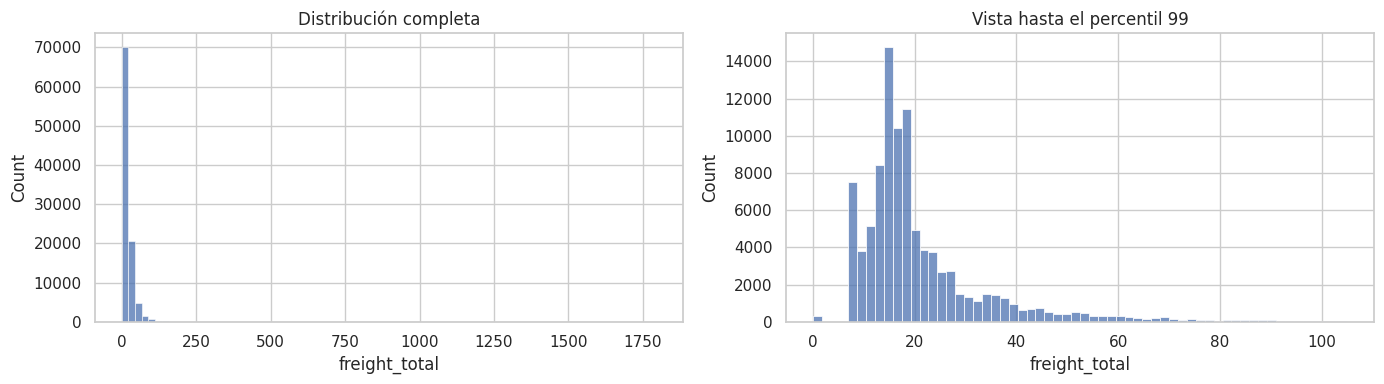

In [8]:
initial_rows = len(data)
data = data.dropna(subset=["order_purchase_timestamp", "freight_total"]).copy()
data = data[
    np.isfinite(data["freight_total"])
    & (data["freight_total"] >= 0)
    & (data["n_items"] > 0)
].copy()

display(pd.DataFrame({
    "indicador": ["Iniciales", "Válidas", "Retiradas", "Flete cero"],
    "valor": [
        initial_rows, len(data), initial_rows - len(data),
        int((data["freight_total"] == 0).sum())
    ],
}))
display(data["freight_total"].quantile([0, .25, .5, .75, .95, .99, 1]).to_frame())

p99 = data["freight_total"].quantile(.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data["freight_total"], bins=80, ax=axes[0])
axes[0].set_title("Distribución completa")
sns.histplot(data.loc[data["freight_total"] <= p99, "freight_total"], bins=60, ax=axes[1])
axes[1].set_title("Vista hasta el percentil 99")
plt.tight_layout()
plt.show()

## 5. Ingeniería de características

Se crean distancia geográfica, peso volumétrico, peso cobrable, interacciones físicas, contexto temporal y tipo de ruta. El divisor 6000 es una aproximación académica y debería adaptarse al transportista real.

In [9]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1.astype(float), lon1.astype(float), lat2.astype(float), lon2.astype(float)]
    )
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(a))

data["distance_km"] = haversine_km(
    data["seller_lat"], data["seller_lng"], data["customer_lat"], data["customer_lng"]
)
data["same_state"] = data["main_seller_state"].eq(data["customer_state"]).astype("Int64")
data["state_pair"] = (
    data["main_seller_state"].fillna("DESCONOCIDO")
    + "_" + data["customer_state"].fillna("DESCONOCIDO")
)

purchase = data["order_purchase_timestamp"]
data["purchase_year"] = purchase.dt.year
data["purchase_month"] = purchase.dt.month
data["purchase_dayofweek"] = purchase.dt.dayofweek
data["purchase_hour"] = purchase.dt.hour
data["purchase_is_weekend"] = purchase.dt.dayofweek.isin([5, 6]).astype(int)

data["weight_total_kg"] = data["weight_total_g"] / 1000
data["volumetric_weight_kg"] = data["volume_total_cm3"] / 6000
data["chargeable_weight_kg"] = data[["weight_total_kg", "volumetric_weight_kg"]].max(axis=1)
safe_items = data["n_items"].replace(0, np.nan)
data["avg_item_price"] = data["price_total"] / safe_items
data["weight_per_item_kg"] = data["weight_total_kg"] / safe_items
data["volume_per_item_cm3"] = data["volume_total_cm3"] / safe_items
data["distance_x_chargeable_weight"] = data["distance_km"] * data["chargeable_weight_kg"]
data["distance_x_items"] = data["distance_km"] * data["n_items"]

display(data[[
    "freight_total", "distance_km", "weight_total_kg",
    "volumetric_weight_kg", "chargeable_weight_kg",
    "distance_x_chargeable_weight"
]].describe().T)

,count,mean,std,min,25%,50%,75%,max
freight_total,98666.0,22.823562,21.650909,0.0,13.850000,17.170000,24.040000,1794.960000
distance_km,98177.0,601.545034,595.519326,0.0,184.974749,433.732079,799.251722,8677.871551
weight_total_kg,98666.0,2.390028,4.773240,0.0,0.300000,0.750000,2.066750,184.400000
volumetric_weight_kg,98666.0,2.900238,5.067028,0.0,0.494000,1.210000,3.312000,246.000000
chargeable_weight_kg,98666.0,3.358659,5.566059,0.0,0.584000,1.365333,3.920000,246.000000
distance_x_chargeable_weight,98177.0,1977.503021,4965.274134,0.0,167.500352,562.599606,1853.489756,290354.178408


## 6. EDA de las relaciones principales

Estos gráficos permiten detectar relaciones útiles y errores de construcción. Se usa una muestra reproducible únicamente para visualizar.

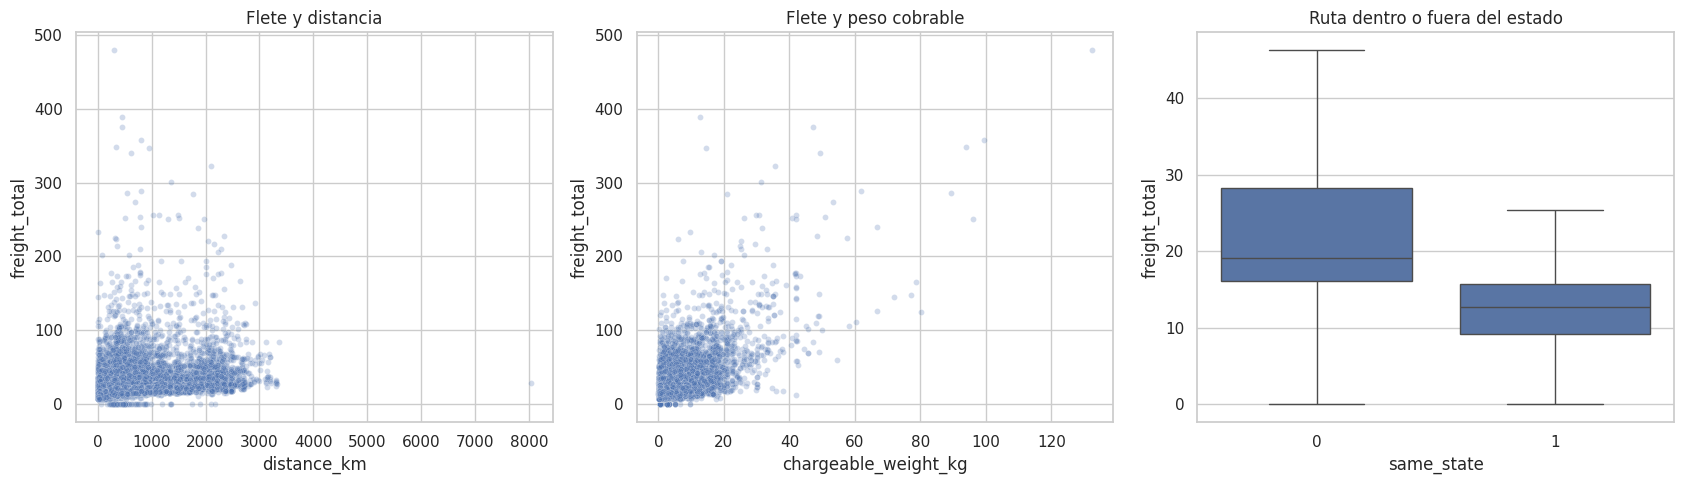

In [10]:
sample = data.sample(min(20000, len(data)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=sample, x="distance_km", y="freight_total", alpha=.25, s=18, ax=axes[0])
axes[0].set_title("Flete y distancia")
sns.scatterplot(data=sample, x="chargeable_weight_kg", y="freight_total", alpha=.25, s=18, ax=axes[1])
axes[1].set_title("Flete y peso cobrable")
sns.boxplot(data=data, x="same_state", y="freight_total", showfliers=False, ax=axes[2])
axes[2].set_title("Ruta dentro o fuera del estado")
plt.tight_layout()
plt.show()

## 7. División temporal

Los pedidos se ordenan por fecha: 60 % para entrenamiento, 20 % para validación y 20 % para prueba. La prueba no participa en selección de variables ni de algoritmo.

In [11]:
data = data.sort_values("order_purchase_timestamp").reset_index(drop=True)
n = len(data)
train_end, validation_end = int(n * .60), int(n * .80)
train_data = data.iloc[:train_end].copy()
validation_data = data.iloc[train_end:validation_end].copy()
test_data = data.iloc[validation_end:].copy()

display(pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "filas": [len(train_data), len(validation_data), len(test_data)],
    "inicio": [
        train_data["order_purchase_timestamp"].min(),
        validation_data["order_purchase_timestamp"].min(),
        test_data["order_purchase_timestamp"].min(),
    ],
    "fin": [
        train_data["order_purchase_timestamp"].max(),
        validation_data["order_purchase_timestamp"].max(),
        test_data["order_purchase_timestamp"].max(),
    ],
}))

,conjunto,filas,inicio,fin
0,Entrenamiento,59199,2016-09-04 21:15:19,2018-03-02 14:29:28
1,Validación,19733,2018-03-02 14:33:10,2018-05-25 10:33:39
2,Prueba,19734,2018-05-25 10:38:16,2018-09-03 09:06:57


## 8. Historial previo de vendedor y ruta

El historial se calcula sin mirar el pedido actual ni el futuro. En entrenamiento se usa una mediana expansiva desplazada; validación solo ve entrenamiento y prueba solo ve el bloque de desarrollo.

In [12]:
def prior_median(frame, group_column):
    ordered = frame.sort_values("order_purchase_timestamp")
    result = ordered.groupby(group_column, dropna=False)["freight_total"].transform(
        lambda values: values.shift(1).expanding().median()
    )
    return result.reindex(frame.index)

global_train = train_data["freight_total"].median()
train_data["seller_historical_freight"] = prior_median(train_data, "main_seller_id").fillna(global_train)
train_data["route_historical_freight"] = prior_median(train_data, "state_pair").fillna(global_train)

seller_train = train_data.groupby("main_seller_id", dropna=False)["freight_total"].median()
route_train = train_data.groupby("state_pair", dropna=False)["freight_total"].median()
validation_data["seller_historical_freight"] = validation_data["main_seller_id"].map(seller_train).fillna(global_train)
validation_data["route_historical_freight"] = validation_data["state_pair"].map(route_train).fillna(global_train)

development_data = pd.concat([train_data, validation_data]).sort_values("order_purchase_timestamp")
global_development = development_data["freight_total"].median()
seller_development = development_data.groupby("main_seller_id", dropna=False)["freight_total"].median()
route_development = development_data.groupby("state_pair", dropna=False)["freight_total"].median()
test_data["seller_historical_freight"] = test_data["main_seller_id"].map(seller_development).fillna(global_development)
test_data["route_historical_freight"] = test_data["state_pair"].map(route_development).fillna(global_development)

## 8.1. Zonas logísticas obtenidas de las coordenadas

Dos rutas con la misma distancia pueden atravesar zonas logísticas muy distintas. Para representar ese contexto agrupamos las coordenadas en 20 zonas mediante K-Means.

El agrupamiento se ajusta únicamente con las coordenadas del entrenamiento y no utiliza el precio del flete. Después se asigna una zona al vendedor, otra al cliente y se forma el par origen-destino. Las coordenadas siguen sin entrar directamente a los modelos.

In [13]:
from sklearn.cluster import KMeans

N_GEO_CLUSTERS = 20

train_seller_coordinates = train_data[[
    "seller_lat", "seller_lng"
]].to_numpy()
train_customer_coordinates = train_data[[
    "customer_lat", "customer_lng"
]].to_numpy()
train_coordinates = np.vstack([
    train_seller_coordinates,
    train_customer_coordinates,
])

geo_cluster_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("kmeans", KMeans(
        n_clusters=N_GEO_CLUSTERS,
        n_init=10,
        random_state=RANDOM_STATE,
    )),
])
geo_cluster_pipeline.fit(train_coordinates)

def add_geographic_clusters(frame):
    frame = frame.copy()
    seller_cluster = geo_cluster_pipeline.predict(
        frame[["seller_lat", "seller_lng"]].to_numpy()
    )
    customer_cluster = geo_cluster_pipeline.predict(
        frame[["customer_lat", "customer_lng"]].to_numpy()
    )
    frame["seller_geo_cluster"] = seller_cluster.astype(str)
    frame["customer_geo_cluster"] = customer_cluster.astype(str)
    frame["geo_cluster_pair"] = (
        frame["seller_geo_cluster"]
        + "_"
        + frame["customer_geo_cluster"]
    )
    return frame

train_data = add_geographic_clusters(train_data)
validation_data = add_geographic_clusters(validation_data)
test_data = add_geographic_clusters(test_data)
development_data = pd.concat(
    [train_data, validation_data],
    axis=0,
).sort_values("order_purchase_timestamp")

display(train_data[[
    "seller_geo_cluster",
    "customer_geo_cluster",
    "geo_cluster_pair",
]].head())

,seller_geo_cluster,customer_geo_cluster,geo_cluster_pair
0,19,4,19_4
1,18,6,18_6
2,18,10,18_10
3,2,2,2_2
4,16,2,16_2


## 9. Catálogo de variables y prevención de fuga

La columna origen distingue datos originales de variables creadas. Se excluye el objetivo y cualquier ratio que contenga freight_total.

In [14]:
FEATURE_CATALOG = {
    "n_items": ("Dataset original", "Líneas de artículos"),
    "n_products": ("Dataset original", "Productos diferentes"),
    "n_sellers": ("Dataset original", "Vendedores diferentes"),
    "price_total": ("Dataset original", "Valor de productos"),
    "weight_total_g": ("Dataset original", "Peso total"),
    "volume_total_cm3": ("Ingeniería de características", "Volumen total"),
    "main_category": ("Dataset original", "Categoría principal"),
    "customer_state": ("Dataset original", "Estado del cliente"),
    "main_seller_state": ("Dataset original", "Estado del vendedor"),
    "purchase_year": ("Ingeniería de características", "Año"),
    "purchase_month": ("Ingeniería de características", "Mes"),
    "purchase_dayofweek": ("Ingeniería de características", "Día semanal"),
    "purchase_hour": ("Ingeniería de características", "Hora"),
    "purchase_is_weekend": ("Ingeniería de características", "Fin de semana"),
    "distance_km": ("Ingeniería de características", "Distancia geográfica"),
    "same_state": ("Ingeniería de características", "Mismo estado"),
    "state_pair": ("Ingeniería de características", "Par de estados"),
    "weight_total_kg": ("Ingeniería de características", "Peso en kg"),
    "volumetric_weight_kg": ("Ingeniería de características", "Peso volumétrico"),
    "chargeable_weight_kg": ("Ingeniería de características", "Peso cobrable"),
    "avg_item_price": ("Ingeniería de características", "Precio promedio"),
    "weight_per_item_kg": ("Ingeniería de características", "Peso por artículo"),
    "volume_per_item_cm3": ("Ingeniería de características", "Volumen por artículo"),
    "distance_x_chargeable_weight": ("Ingeniería de características", "Distancia por peso"),
    "distance_x_items": ("Ingeniería de características", "Distancia por cantidad"),
    "seller_historical_freight": ("Ingeniería de características", "Historial del vendedor"),
    "route_historical_freight": ("Ingeniería de características", "Historial de la ruta"),
    "seller_geo_cluster": ("Ingeniería de características", "Zona logística del vendedor"),
    "customer_geo_cluster": ("Ingeniería de características", "Zona logística del cliente"),
    "geo_cluster_pair": ("Ingeniería de características", "Par de zonas logísticas"),
}
ALL_FEATURES = list(FEATURE_CATALOG)
TARGET = "freight_total"
feature_catalog_df = pd.DataFrame([
    {"variable": variable, "origen": origin, "descripcion": description}
    for variable, (origin, description) in FEATURE_CATALOG.items()
])
display(feature_catalog_df)
print("Variables candidatas:", len(ALL_FEATURES))

,variable,origen,descripcion
0,n_items,Dataset original,Líneas de artículos
1,n_products,Dataset original,Productos diferentes
2,n_sellers,Dataset original,Vendedores diferentes
3,price_total,Dataset original,Valor de productos
4,weight_total_g,Dataset original,Peso total
5,volume_total_cm3,Ingeniería de características,Volumen total
6,main_category,Dataset original,Categoría principal
7,customer_state,Dataset original,Estado del cliente
8,main_seller_state,Dataset original,Estado del vendedor
9,purchase_year,Ingeniería de características,Año


Variables candidatas: 30


## 10. Preprocesamiento

Los números se imputan con mediana y se escalan. Las categorías se imputan con la moda y se codifican. Cada subconjunto tendrá su propio preprocesador dentro del pipeline.

In [15]:
CATEGORICAL = [
    "main_category", "customer_state", "main_seller_state",
    "state_pair", "seller_geo_cluster",
    "customer_geo_cluster", "geo_cluster_pair",
]

def build_preprocessor(features):
    categorical = [column for column in features if column in CATEGORICAL]
    numeric = [column for column in features if column not in categorical]
    transformers = []
    if numeric:
        transformers.append(("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric))
    if categorical:
        transformers.append(("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
        ]), categorical))
    return ColumnTransformer(transformers, remainder="drop")

## 11. Selección de variables

Un XGBoost auxiliar se ajusta solo con entrenamiento. Permutation Importance mide en validación cuánto aumenta el MAE cuando se desordena cada variable. La tabla mostrará posición, variable, origen, descripción e importancia.

,posicion,variable,importancia_mae,desviacion,origen,descripcion
0,1,n_items,1.853504,0.008302,Dataset original,Líneas de artículos
1,2,distance_x_items,0.956865,0.014361,Ingeniería de características,Distancia por cantidad
2,3,distance_x_chargeable_weight,0.853047,0.010992,Ingeniería de características,Distancia por peso
3,4,route_historical_freight,0.756843,0.012095,Ingeniería de características,Historial de la ruta
4,5,weight_total_g,0.602023,0.006190,Dataset original,Peso total
5,6,same_state,0.507782,0.004635,Ingeniería de características,Mismo estado
6,7,price_total,0.500282,0.004045,Dataset original,Valor de productos
7,8,volume_total_cm3,0.426757,0.007670,Ingeniería de características,Volumen total
8,9,chargeable_weight_kg,0.238521,0.005373,Ingeniería de características,Peso cobrable
9,10,seller_historical_freight,0.218724,0.002349,Ingeniería de características,Historial del vendedor


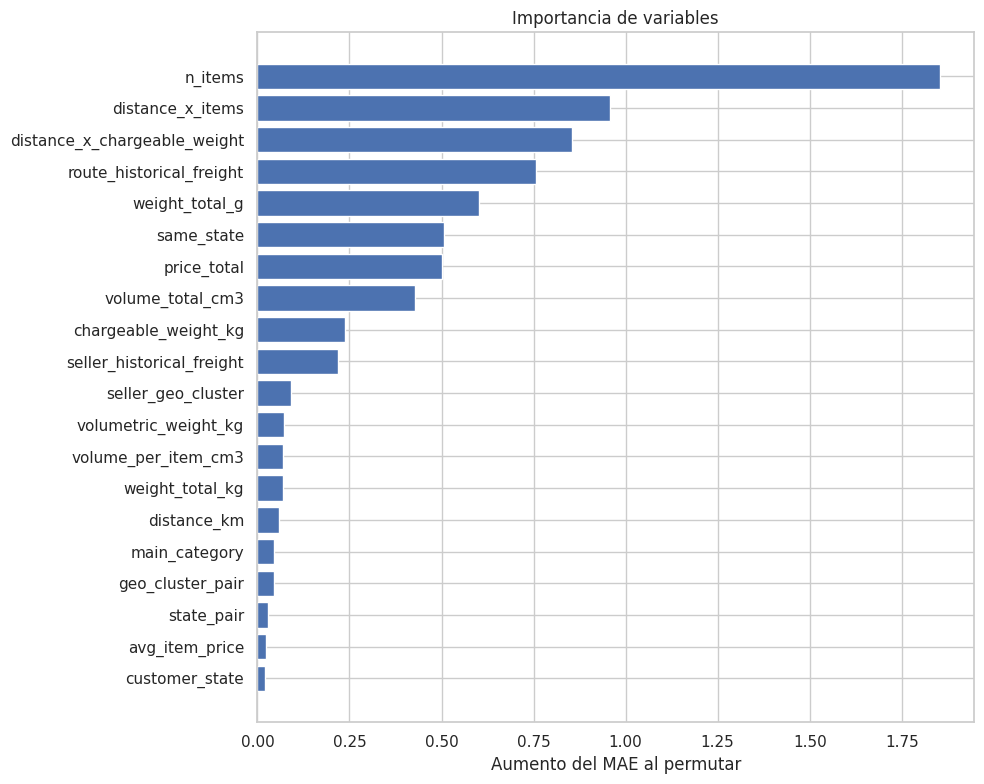

In [16]:
USE_GPU_FOR_XGBOOST = True
xgb_device = {"tree_method": "hist", "device": "cuda" if USE_GPU_FOR_XGBOOST else "cpu"}

selector_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(ALL_FEATURES)),
    ("model", XGBRegressor(
        n_estimators=450, learning_rate=.05, max_depth=7,
        min_child_weight=4, subsample=.85, colsample_bytree=.85,
        reg_alpha=.05, reg_lambda=1.5, objective="reg:absoluteerror",
        random_state=RANDOM_STATE, n_jobs=-1, **xgb_device
    )),
])

RUN_FEATURE_SELECTION = True
if RUN_FEATURE_SELECTION:
    selector_pipeline.fit(train_data[ALL_FEATURES], train_data[TARGET])
    permutation = permutation_importance(
        selector_pipeline,
        validation_data[ALL_FEATURES],
        validation_data[TARGET],
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=1,  # Evita predicciones GPU simultáneas durante la permutación
    )
    feature_importance_df = pd.DataFrame({
        "variable": ALL_FEATURES,
        "importancia_mae": permutation.importances_mean,
        "desviacion": permutation.importances_std,
    }).merge(feature_catalog_df, on="variable", how="left")
    feature_importance_df = feature_importance_df.sort_values(
        "importancia_mae", ascending=False
    ).reset_index(drop=True)
    feature_importance_df.insert(0, "posicion", np.arange(1, len(feature_importance_df) + 1))
    display(feature_importance_df)

    plot_data = feature_importance_df.head(20).sort_values("importancia_mae")
    plt.figure(figsize=(10, 8))
    plt.barh(plot_data["variable"], plot_data["importancia_mae"])
    plt.xlabel("Aumento del MAE al permutar")
    plt.title("Importancia de variables")
    plt.tight_layout()
    plt.show()
else:
    print("Selección desactivada. Cambia RUN_FEATURE_SELECTION a True.")

## 12. Construcción de subconjuntos

Se crean top 5, top 10, top 15 y todas. La reducción no es obligatoria: validación decidirá qué cantidad conviene.

In [17]:
if RUN_FEATURE_SELECTION:
    ranked = feature_importance_df["variable"].tolist()
    FEATURE_SUBSETS = {
        "Top 5": ranked[:5],
        "Top 10": ranked[:10],
        "Top 15": ranked[:15],
        "Todas": ranked,
    }
    display(pd.DataFrame([
        {"subconjunto": name, "cantidad": len(features), "variables": ", ".join(features)}
        for name, features in FEATURE_SUBSETS.items()
    ]))
else:
    FEATURE_SUBSETS = {}

,subconjunto,cantidad,variables
0,Top 5,5,"n_items, distance_x_items, distance_x_chargeab..."
1,Top 10,10,"n_items, distance_x_items, distance_x_chargeab..."
2,Top 15,15,"n_items, distance_x_items, distance_x_chargeab..."
3,Todas,30,"n_items, distance_x_items, distance_x_chargeab..."


## 12.1. Revisión de fletes altos y extremos

Antes de entrenar el modelo caro revisamos cuántos pedidos superan 30, 60, 100 y 300 BRL. También mostramos los pedidos más costosos y comprobamos si les faltan datos físicos o geográficos.

Esta revisión no elimina registros. Un pedido extremo solo debería retirarse si se demuestra que es duplicado, imposible o producto de un error de datos.

In [18]:
high_cost_summary = pd.DataFrame({
    "condicion": [
        "Más de 30 BRL",
        "Más de 60 BRL",
        "Más de 100 BRL",
        "Más de 300 BRL",
    ],
    "pedidos_entrenamiento": [
        int((train_data[TARGET] > 30).sum()),
        int((train_data[TARGET] > 60).sum()),
        int((train_data[TARGET] > 100).sum()),
        int((train_data[TARGET] > 300).sum()),
    ],
})
high_cost_summary["porcentaje"] = (
    high_cost_summary["pedidos_entrenamiento"]
    / len(train_data)
    * 100
)
display(
    high_cost_summary.style.format({
        "porcentaje": "{:.2f}%"
    })
)

extreme_columns = [
    "order_id",
    "order_purchase_timestamp",
    TARGET,
    "distance_km",
    "weight_total_kg",
    "volumetric_weight_kg",
    "chargeable_weight_kg",
    "n_items",
    "price_total",
    "customer_state",
    "main_seller_state",
]
extreme_orders = (
    train_data.nlargest(20, TARGET)[extreme_columns]
    .reset_index(drop=True)
)
display(extreme_orders)

extreme_quality = pd.DataFrame({
    "indicador": [
        "IDs duplicados",
        "Distancia ausente",
        "Peso cobrable ausente",
        "Precio de productos ausente",
    ],
    "valor": [
        int(extreme_orders["order_id"].duplicated().sum()),
        int(extreme_orders["distance_km"].isna().sum()),
        int(
            extreme_orders[
                "chargeable_weight_kg"
            ].isna().sum()
        ),
        int(extreme_orders["price_total"].isna().sum()),
    ],
})
display(extreme_quality)

,condicion,pedidos_entrenamiento,porcentaje
0,Más de 30 BRL,9711,16.40%
1,Más de 60 BRL,2048,3.46%
2,Más de 100 BRL,539,0.91%
3,Más de 300 BRL,23,0.04%


,order_id,order_purchase_timestamp,freight_total,distance_km,weight_total_kg,volumetric_weight_kg,chargeable_weight_kg,n_items,price_total,customer_state,main_seller_state
0,2455cbeb73fd04b170ca2504662f95ce,2017-06-20 12:39:46,1002.29,378.697770,154.200,246.000000,246.000000,6,419.40,PR,SP
1,cfed507ac357129f750f05a0d7d71b15,2018-02-25 12:15:02,711.33,1546.988543,90.000,93.600000,93.600000,3,1380.00,MA,MG
2,71dab1155600756af6de79de92e712e3,2018-02-01 18:32:02,626.64,1664.708286,86.585,113.606000,113.606000,11,1361.89,BA,SP
3,725cf8e9c24e679a8a5a32cb92c9ce1e,2017-06-08 21:00:36,497.42,1996.477735,60.000,83.875000,83.875000,2,1570.00,PE,SP
4,5bd06bab48e0423fc35d1c236d48a6bb,2017-05-11 19:17:49,497.08,2074.787539,60.000,83.875000,83.875000,2,1520.00,PE,SP
5,be382a9e1ed25128148b97d6bfdb21af,2017-11-04 17:29:15,479.28,309.682892,129.336,132.266667,132.266667,8,1559.92,RJ,SP
6,85c467a504e5796387bb68fe2adcc256,2018-01-12 14:52:12,436.24,1765.301386,60.000,56.320000,60.000000,2,1767.80,BA,PR
7,73cbd9a357e885c9034b3df9d50482bb,2017-11-17 19:42:29,389.25,1878.827891,69.900,69.745000,69.900000,3,1038.00,PE,RJ
8,f80549a97eb203e1566e026ab66f045b,2017-09-12 10:31:42,388.10,454.379297,9.220,12.750000,12.750000,10,1379.00,SP,MG
9,e8e6d889f4d8a89fdcae9bdd473117d7,2017-08-09 20:09:55,383.64,994.618566,79.200,82.134000,82.134000,3,2096.94,SC,MG


,indicador,valor
0,IDs duplicados,0
1,Distancia ausente,0
2,Peso cobrable ausente,0
3,Precio de productos ausente,0


## 12.2. Selección de variables para el modelo caro

El ranking general puede favorecer las variables que funcionan bien en los pedidos comunes. Por eso construimos un segundo ranking usando únicamente fletes superiores a 30 BRL.

Dentro de ese grupo, los pedidos mayores de 60 BRL reciben peso triple. Permutation Importance medirá cuánto empeora el error ponderado cuando se altera cada variable.

In [19]:
HIGH_FREIGHT_LIMIT = 30.0
EXTREME_FREIGHT_LIMIT = 60.0
EXTREME_FREIGHT_WEIGHT = 3.0


high_train_mask = train_data[TARGET] > HIGH_FREIGHT_LIMIT
high_validation_mask = (
    validation_data[TARGET] > HIGH_FREIGHT_LIMIT
)

high_train_weights = np.where(
    train_data.loc[
        high_train_mask, TARGET
    ].to_numpy() > EXTREME_FREIGHT_LIMIT,
    EXTREME_FREIGHT_WEIGHT,
    1.0,
)

high_selector_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(ALL_FEATURES)),
    ("model", XGBRegressor(
        n_estimators=550,
        learning_rate=.04,
        max_depth=7,
        min_child_weight=3,
        subsample=.90,
        colsample_bytree=.90,
        reg_alpha=.05,
        reg_lambda=1.5,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **xgb_device,
    )),
])

def negative_weighted_high_mae(estimator, features, target):
    prediction = estimator.predict(features)
    weights = np.where(
        np.asarray(target) > EXTREME_FREIGHT_LIMIT,
        EXTREME_FREIGHT_WEIGHT,
        1.0,
    )
    return -np.average(
        np.abs(np.asarray(target) - prediction),
        weights=weights,
    )

### Ejecución del ranking especializado

La selección se mantiene apagada. Al activarla se generará una tabla y un gráfico exclusivos del modelo caro, además de sus propios subconjuntos top 5, top 10, top 15 y todas.

,posicion,variable,importancia_mae_ponderado,desviacion,origen,descripcion
0,1,n_items,2.310790,0.070668,Dataset original,Líneas de artículos
1,2,chargeable_weight_kg,2.266536,0.075880,Ingeniería de características,Peso cobrable
2,3,volume_total_cm3,1.543138,0.085641,Ingeniería de características,Volumen total
3,4,price_total,1.309379,0.124139,Dataset original,Valor de productos
4,5,distance_x_chargeable_weight,1.284898,0.056238,Ingeniería de características,Distancia por peso
5,6,route_historical_freight,1.237246,0.125350,Ingeniería de características,Historial de la ruta
6,7,distance_x_items,0.467768,0.091054,Ingeniería de características,Distancia por cantidad
7,8,seller_historical_freight,0.392306,0.024815,Ingeniería de características,Historial del vendedor
8,9,volume_per_item_cm3,0.387187,0.060363,Ingeniería de características,Volumen por artículo
9,10,weight_total_g,0.360889,0.073005,Dataset original,Peso total


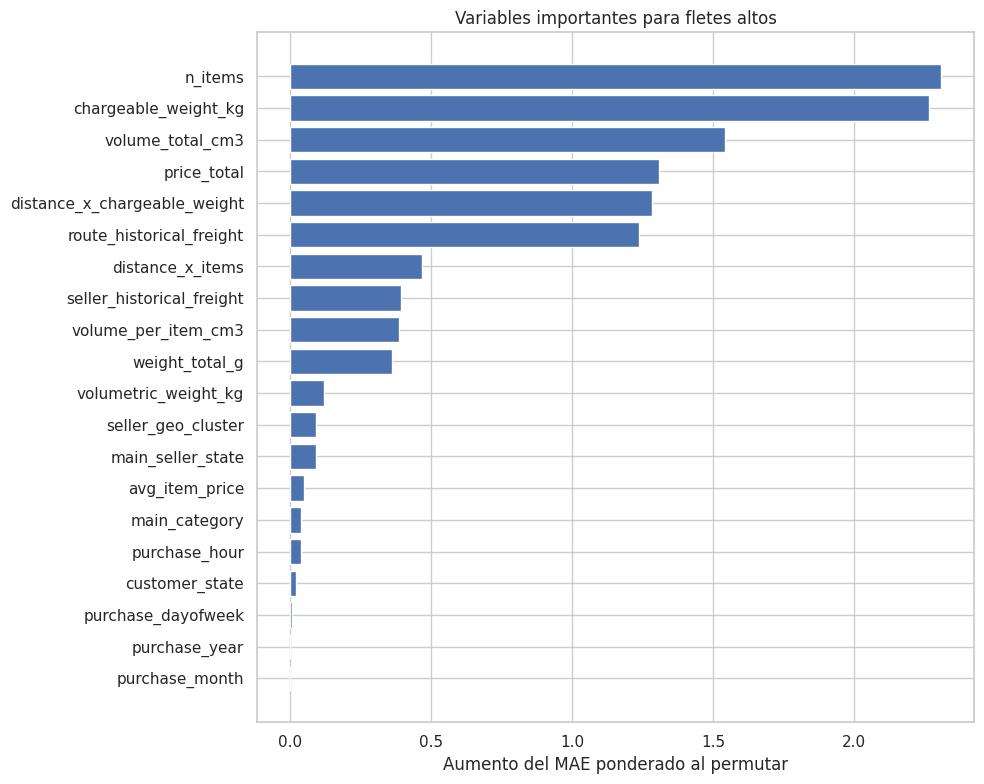

,subconjunto,cantidad,variables
0,Top 5,5,"n_items, chargeable_weight_kg, volume_total_cm..."
1,Top 10,10,"n_items, chargeable_weight_kg, volume_total_cm..."
2,Top 15,15,"n_items, chargeable_weight_kg, volume_total_cm..."
3,Todas,30,"n_items, chargeable_weight_kg, volume_total_cm..."


In [20]:
RUN_HIGH_FEATURE_SELECTION = True

if RUN_HIGH_FEATURE_SELECTION:
    high_selector_pipeline.fit(
        train_data.loc[high_train_mask, ALL_FEATURES],
        train_data.loc[high_train_mask, TARGET],
        model__sample_weight=high_train_weights,
    )

    high_permutation = permutation_importance(
        high_selector_pipeline,
        validation_data.loc[
            high_validation_mask, ALL_FEATURES
        ],
        validation_data.loc[
            high_validation_mask, TARGET
        ],
        scoring=negative_weighted_high_mae,
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

    high_feature_importance_df = pd.DataFrame({
        "variable": ALL_FEATURES,
        "importancia_mae_ponderado": (
            high_permutation.importances_mean
        ),
        "desviacion": high_permutation.importances_std,
    }).merge(
        feature_catalog_df,
        on="variable",
        how="left",
    )
    high_feature_importance_df = (
        high_feature_importance_df.sort_values(
            "importancia_mae_ponderado",
            ascending=False,
        )
        .reset_index(drop=True)
    )
    high_feature_importance_df.insert(
        0,
        "posicion",
        np.arange(
            1,
            len(high_feature_importance_df) + 1,
        ),
    )
    display(high_feature_importance_df)

    high_plot = (
        high_feature_importance_df.head(20)
        .sort_values("importancia_mae_ponderado")
    )
    plt.figure(figsize=(10, 8))
    plt.barh(
        high_plot["variable"],
        high_plot["importancia_mae_ponderado"],
    )
    plt.xlabel(
        "Aumento del MAE ponderado al permutar"
    )
    plt.title(
        "Variables importantes para fletes altos"
    )
    plt.tight_layout()
    plt.show()

    high_ranked_features = (
        high_feature_importance_df[
            "variable"
        ].tolist()
    )
    HIGH_FEATURE_SUBSETS = {
        "Top 5": high_ranked_features[:5],
        "Top 10": high_ranked_features[:10],
        "Top 15": high_ranked_features[:15],
        "Todas": high_ranked_features,
    }
    display(pd.DataFrame([
        {
            "subconjunto": name,
            "cantidad": len(features),
            "variables": ", ".join(features),
        }
        for name, features
        in HIGH_FEATURE_SUBSETS.items()
    ]))
else:
    HIGH_FEATURE_SUBSETS = {}
    print(
        "Selección para fletes altos desactivada. "
        "Cambia RUN_HIGH_FEATURE_SELECTION a True."
    )

## 13. Clasificación previa del tipo de flete

Creamos una etiqueta auxiliar: 0 para fletes de hasta 30 BRL y 1 para fletes mayores de 30 BRL. Esta etiqueta solo se usa durante el entrenamiento.

Se comparan Regresión logística, Random Forest y XGBoost como clasificadores. Como los fletes altos son minoría, se balancean las clases. Además de F1 y ROC AUC, prestamos atención al recall de la clase alta: un recall bajo enviaría pedidos caros al regresor normal.

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier

HIGH_FREIGHT_LIMIT = 30.0

y_train_gate = (train_data[TARGET] > HIGH_FREIGHT_LIMIT).astype(int)
y_validation_gate = (
    validation_data[TARGET] > HIGH_FREIGHT_LIMIT
).astype(int)
y_test_gate = (test_data[TARGET] > HIGH_FREIGHT_LIMIT).astype(int)

class_summary = pd.DataFrame({
    "clase": ["Flete normal", "Flete alto"],
    "pedidos_entrenamiento": [
        int((y_train_gate == 0).sum()),
        int((y_train_gate == 1).sum()),
    ],
    "porcentaje": [
        (y_train_gate == 0).mean() * 100,
        (y_train_gate == 1).mean() * 100,
    ],
})
display(class_summary.style.format({"porcentaje": "{:.1f}%"}))

positive_count = max(int((y_train_gate == 1).sum()), 1)
negative_count = int((y_train_gate == 0).sum())
scale_pos_weight = negative_count / positive_count

CLASSIFIER_MODELS = {
    "Regresión logística": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        max_depth=20,
        min_samples_leaf=3,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=450,
        learning_rate=.05,
        max_depth=7,
        min_child_weight=4,
        subsample=.85,
        colsample_bytree=.85,
        reg_alpha=.05,
        reg_lambda=1.5,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **xgb_device,
    ),
}

,clase,pedidos_entrenamiento,porcentaje
0,Flete normal,49488,83.6%
1,Flete alto,9711,16.4%


### Comparación del clasificador

Cada clasificador se prueba con top 5, top 10, top 15 y todas las variables. También probamos varios umbrales de probabilidad. Un umbral menor detecta más fletes altos, aunque puede enviar algunos pedidos normales al regresor especializado.

Elegimos entre las alternativas con recall mínimo de 80 %. Dentro de ese grupo gana el mayor F1. Si ninguna alcanza ese recall, se conserva la de mayor recall.

In [22]:
RUN_GATE_TRAINING = True
GATE_THRESHOLDS = [0.25, 0.35, 0.45, 0.50]
MIN_HIGH_RECALL = 0.80

gate_results = []
trained_gate_pipelines = {}

if RUN_GATE_TRAINING:
    if not FEATURE_SUBSETS:
        raise RuntimeError(
            "Ejecuta primero la selección de variables y los subconjuntos."
        )

    for subset_name, features in FEATURE_SUBSETS.items():
        for model_name, model in CLASSIFIER_MODELS.items():
            print(f"Clasificador: {model_name} con {subset_name}")
            start = time.perf_counter()

            pipeline = Pipeline([
                ("preprocessor", build_preprocessor(features)),
                ("model", clone(model)),
            ])
            pipeline.fit(train_data[features], y_train_gate)
            probability = pipeline.predict_proba(
                validation_data[features]
            )[:, 1]

            trained_gate_pipelines[(subset_name, model_name)] = pipeline
            elapsed = time.perf_counter() - start
            auc = roc_auc_score(y_validation_gate, probability)

            for threshold in GATE_THRESHOLDS:
                predicted_class = (probability >= threshold).astype(int)
                gate_results.append({
                    "subconjunto": subset_name,
                    "cantidad_variables": len(features),
                    "modelo": model_name,
                    "umbral": threshold,
                    "precision_alto": precision_score(
                        y_validation_gate,
                        predicted_class,
                        zero_division=0,
                    ),
                    "recall_alto": recall_score(
                        y_validation_gate,
                        predicted_class,
                        zero_division=0,
                    ),
                    "F1_alto": f1_score(
                        y_validation_gate,
                        predicted_class,
                        zero_division=0,
                    ),
                    "ROC_AUC": auc,
                    "accuracy": accuracy_score(
                        y_validation_gate,
                        predicted_class,
                    ),
                    "segundos": elapsed,
                })

    gate_results_df = pd.DataFrame(gate_results)
    eligible_gate = gate_results_df[
        gate_results_df["recall_alto"] >= MIN_HIGH_RECALL
    ].copy()

    if eligible_gate.empty:
        gate_winner = gate_results_df.sort_values(
            ["recall_alto", "F1_alto", "precision_alto"],
            ascending=[False, False, False],
        ).iloc[0]
    else:
        gate_winner = eligible_gate.sort_values(
            ["F1_alto", "precision_alto", "ROC_AUC"],
            ascending=[False, False, False],
        ).iloc[0]

    gate_subset_name = gate_winner["subconjunto"]
    gate_model_name = gate_winner["modelo"]
    gate_threshold = float(gate_winner["umbral"])
    gate_features = FEATURE_SUBSETS[gate_subset_name]
    selected_gate_pipeline = trained_gate_pipelines[
        (gate_subset_name, gate_model_name)
    ]

    display(
        gate_results_df.sort_values(
            ["F1_alto", "recall_alto"],
            ascending=[False, False],
        ).style.format({
            "umbral": "{:.2f}",
            "precision_alto": "{:.3f}",
            "recall_alto": "{:.3f}",
            "F1_alto": "{:.3f}",
            "ROC_AUC": "{:.3f}",
            "accuracy": "{:.3f}",
            "segundos": "{:.2f}",
        })
    )

    display(Markdown(
        f"**Clasificador elegido:** {gate_model_name} con "
        f"{gate_subset_name}, umbral {gate_threshold:.2f}, "
        f"recall {gate_winner['recall_alto']:.3f} y "
        f"F1 {gate_winner['F1_alto']:.3f}."
    ))
else:
    print("Clasificación desactivada. Cambia RUN_GATE_TRAINING a True.")

Clasificador: Regresión logística con Top 5
Clasificador: Random Forest con Top 5
Clasificador: XGBoost con Top 5
Clasificador: Regresión logística con Top 10
Clasificador: Random Forest con Top 10
Clasificador: XGBoost con Top 10
Clasificador: Regresión logística con Top 15
Clasificador: Random Forest con Top 15
Clasificador: XGBoost con Top 15
Clasificador: Regresión logística con Todas
Clasificador: Random Forest con Todas
Clasificador: XGBoost con Todas


,subconjunto,cantidad_variables,modelo,umbral,precision_alto,recall_alto,F1_alto,ROC_AUC,accuracy,segundos
19,Top 10,10,Random Forest,0.50,0.800,0.779,0.789,0.957,0.927,15.02
30,Top 15,15,Random Forest,0.45,0.779,0.798,0.788,0.961,0.925,12.71
31,Top 15,15,Random Forest,0.50,0.795,0.781,0.788,0.961,0.927,12.71
18,Top 10,10,Random Forest,0.45,0.780,0.794,0.787,0.957,0.925,15.02
47,Todas,30,XGBoost,0.50,0.771,0.803,0.787,0.960,0.924,2.38
35,Top 15,15,XGBoost,0.50,0.765,0.809,0.786,0.961,0.923,1.52
46,Todas,30,XGBoost,0.45,0.758,0.813,0.785,0.960,0.922,2.38
34,Top 15,15,XGBoost,0.45,0.752,0.818,0.784,0.961,0.921,1.52
23,Top 10,10,XGBoost,0.50,0.757,0.809,0.782,0.960,0.921,1.20
22,Top 10,10,XGBoost,0.45,0.746,0.820,0.781,0.960,0.920,1.20


**Clasificador elegido:** XGBoost con Todas, umbral 0.50, recall 0.803 y F1 0.787.

## 14. Regresores especializados y búsqueda controlada

El regresor normal conserva la comparación habitual entre Regresión lineal, Random Forest y XGBoost usando el ranking general.

El regresor caro usa su ranking propio y prueba variantes adicionales:

- entrenamiento normal;
- entrenamiento ponderado, dando peso triple a fletes mayores de 60 BRL;
- dos configuraciones de Random Forest;
- XGBoost que minimiza error absoluto;
- XGBoost cuantílico al percentil 70, pensado para reducir la subestimación.

Las variantes siguen perteneciendo a las mismas tres familias de algoritmos. La búsqueda es deliberadamente pequeña para que pueda ejecutarse en Kaggle.

In [23]:
NORMAL_REGRESSION_MODELS = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=650,
        learning_rate=.04,
        max_depth=7,
        min_child_weight=4,
        subsample=.85,
        colsample_bytree=.85,
        reg_alpha=.05,
        reg_lambda=1.5,
        objective="reg:absoluteerror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **xgb_device,
    ),
}

high_linear = LinearRegression()
high_rf_compact = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
high_rf_flexible = RandomForestRegressor(
    n_estimators=350,
    max_depth=26,
    min_samples_leaf=1,
    max_features=.75,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
high_xgb_mae = XGBRegressor(
    n_estimators=750,
    learning_rate=.035,
    max_depth=7,
    min_child_weight=3,
    subsample=.90,
    colsample_bytree=.90,
    reg_alpha=.03,
    reg_lambda=1.5,
    objective="reg:absoluteerror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **xgb_device,
)
high_xgb_quantile = XGBRegressor(
    n_estimators=750,
    learning_rate=.035,
    max_depth=7,
    min_child_weight=3,
    subsample=.90,
    colsample_bytree=.90,
    reg_alpha=.03,
    reg_lambda=1.5,
    objective="reg:quantileerror",
    quantile_alpha=.70,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **xgb_device,
)

HIGH_MODEL_VARIANTS = {
    "linear_normal": {
        "modelo": "Regresión lineal",
        "estrategia": "Normal",
        "estimator": high_linear,
        "usa_ponderacion": False,
    },
    "linear_weighted": {
        "modelo": "Regresión lineal",
        "estrategia": "Ponderado >60",
        "estimator": high_linear,
        "usa_ponderacion": True,
    },
    "rf_compact_normal": {
        "modelo": "Random Forest",
        "estrategia": "Compacto normal",
        "estimator": high_rf_compact,
        "usa_ponderacion": False,
    },
    "rf_compact_weighted": {
        "modelo": "Random Forest",
        "estrategia": "Compacto ponderado >60",
        "estimator": high_rf_compact,
        "usa_ponderacion": True,
    },
    "rf_flexible_weighted": {
        "modelo": "Random Forest",
        "estrategia": "Flexible ponderado >60",
        "estimator": high_rf_flexible,
        "usa_ponderacion": True,
    },
    "xgb_mae_normal": {
        "modelo": "XGBoost",
        "estrategia": "MAE normal",
        "estimator": high_xgb_mae,
        "usa_ponderacion": False,
    },
    "xgb_mae_weighted": {
        "modelo": "XGBoost",
        "estrategia": "MAE ponderado >60",
        "estimator": high_xgb_mae,
        "usa_ponderacion": True,
    },
    "xgb_quantile_70": {
        "modelo": "XGBoost",
        "estrategia": "Cuantil 0.70",
        "estimator": high_xgb_quantile,
        "usa_ponderacion": False,
    },
}

def regression_metrics(y_true, prediction):
    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": mean_squared_error(y_true, prediction) ** .5,
        "R2": r2_score(y_true, prediction),
        "sesgo": np.mean(
            np.asarray(y_true)
            - np.asarray(prediction)
        ),
    }

### Comparación del regresor normal

Esta parte mantiene el procedimiento anterior. El ganador se elige por menor MAE dentro de los pedidos de hasta 30 BRL.

In [24]:
RUN_NORMAL_REGRESSION = True
normal_results = []
trained_normal_pipelines = {}

normal_train_mask = (
    train_data[TARGET] <= HIGH_FREIGHT_LIMIT
)
normal_validation_mask = (
    validation_data[TARGET] <= HIGH_FREIGHT_LIMIT
)

if RUN_NORMAL_REGRESSION:
    if not FEATURE_SUBSETS:
        raise RuntimeError(
            "Ejecuta primero la selección general."
        )

    for subset_name, features in FEATURE_SUBSETS.items():
        for model_name, model in (
            NORMAL_REGRESSION_MODELS.items()
        ):
            start = time.perf_counter()
            pipeline = Pipeline([
                (
                    "preprocessor",
                    build_preprocessor(features),
                ),
                ("model", clone(model)),
            ])
            pipeline.fit(
                train_data.loc[
                    normal_train_mask, features
                ],
                train_data.loc[
                    normal_train_mask, TARGET
                ],
            )
            prediction = pipeline.predict(
                validation_data.loc[
                    normal_validation_mask, features
                ]
            )
            normal_results.append({
                "subconjunto": subset_name,
                "cantidad_variables": len(features),
                "modelo": model_name,
                **regression_metrics(
                    validation_data.loc[
                        normal_validation_mask, TARGET
                    ],
                    prediction,
                ),
                "segundos": (
                    time.perf_counter() - start
                ),
            })
            trained_normal_pipelines[
                (subset_name, model_name)
            ] = pipeline

    normal_results_df = pd.DataFrame(
        normal_results
    ).sort_values(
        ["MAE", "RMSE", "R2"],
        ascending=[True, True, False],
    )
    normal_winner = normal_results_df.iloc[0]
    normal_features = FEATURE_SUBSETS[
        normal_winner["subconjunto"]
    ]
    selected_normal_pipeline = (
        trained_normal_pipelines[(
            normal_winner["subconjunto"],
            normal_winner["modelo"],
        )]
    )
    display(normal_results_df.style.format({
        "MAE": "R$ {:.2f}",
        "RMSE": "R$ {:.2f}",
        "R2": "{:.3f}",
        "sesgo": "R$ {:.2f}",
        "segundos": "{:.2f}",
    }))
else:
    print(
        "Regresión normal desactivada. "
        "Cambia RUN_NORMAL_REGRESSION a True."
    )

,subconjunto,cantidad_variables,modelo,MAE,RMSE,R2,sesgo,segundos
8,Top 15,15,XGBoost,R$ 2.61,R$ 4.05,0.537,R$ 0.62,2.03
11,Todas,30,XGBoost,R$ 2.62,R$ 4.04,0.538,R$ 0.64,2.99
7,Top 15,15,Random Forest,R$ 2.62,R$ 4.03,0.541,R$ 0.51,10.49
4,Top 10,10,Random Forest,R$ 2.63,R$ 4.01,0.544,R$ 0.49,12.05
5,Top 10,10,XGBoost,R$ 2.64,R$ 4.04,0.538,R$ 0.59,1.68
1,Top 5,5,Random Forest,R$ 2.77,R$ 4.17,0.509,R$ 0.55,9.55
10,Todas,30,Random Forest,R$ 2.77,R$ 4.10,0.526,R$ 0.49,20.30
2,Top 5,5,XGBoost,R$ 2.81,R$ 4.22,0.495,R$ 0.69,1.46
9,Todas,30,Regresión lineal,R$ 2.87,R$ 4.20,0.501,R$ 0.47,3.93
6,Top 15,15,Regresión lineal,R$ 2.98,R$ 4.25,0.489,R$ 0.34,0.24


### Comparación del regresor caro

Cada variante se evalúa en todos los fletes mayores de 30 BRL y también por separado en los superiores a 60 BRL.

Para no mejorar los extremos destruyendo el resto, primero se conservan las opciones cuyo MAE general del segmento caro no supere en más de 10 % al mejor. Entre ellas se elige la que tenga menor MAE por encima de 60 BRL y menor subestimación.

In [25]:
RUN_HIGH_REGRESSION = True
MAX_HIGH_MAE_INCREASE = .10
high_regression_results = []
trained_high_pipelines = {}

if RUN_HIGH_REGRESSION:
    if not HIGH_FEATURE_SUBSETS:
        raise RuntimeError(
            "Ejecuta primero la selección para fletes altos."
        )

    high_train_target = train_data.loc[
        high_train_mask, TARGET
    ]
    high_validation_target = validation_data.loc[
        high_validation_mask, TARGET
    ]
    extreme_validation_mask = (
        high_validation_target > EXTREME_FREIGHT_LIMIT
    )

    for subset_name, features in (
        HIGH_FEATURE_SUBSETS.items()
    ):
        for candidate_key, configuration in (
            HIGH_MODEL_VARIANTS.items()
        ):
            print(
                f"Flete alto: {candidate_key} "
                f"con {subset_name}"
            )
            start = time.perf_counter()
            pipeline = Pipeline([
                (
                    "preprocessor",
                    build_preprocessor(features),
                ),
                (
                    "model",
                    clone(configuration["estimator"]),
                ),
            ])

            fit_parameters = {}
            if configuration["usa_ponderacion"]:
                fit_parameters[
                    "model__sample_weight"
                ] = high_train_weights

            pipeline.fit(
                train_data.loc[
                    high_train_mask, features
                ],
                high_train_target,
                **fit_parameters,
            )
            prediction = pipeline.predict(
                validation_data.loc[
                    high_validation_mask, features
                ]
            )

            extreme_real = high_validation_target.loc[
                extreme_validation_mask
            ].to_numpy()
            extreme_prediction = prediction[
                extreme_validation_mask.to_numpy()
            ]

            result = {
                "candidate_key": candidate_key,
                "subconjunto": subset_name,
                "cantidad_variables": len(features),
                "modelo": configuration["modelo"],
                "estrategia": configuration[
                    "estrategia"
                ],
                "usa_ponderacion": configuration[
                    "usa_ponderacion"
                ],
                **regression_metrics(
                    high_validation_target,
                    prediction,
                ),
                "MAE_mayor_60": mean_absolute_error(
                    extreme_real,
                    extreme_prediction,
                ),
                "sesgo_mayor_60": np.mean(
                    extreme_real
                    - extreme_prediction
                ),
                "segundos": (
                    time.perf_counter() - start
                ),
            }
            high_regression_results.append(result)
            trained_high_pipelines[
                (candidate_key, subset_name)
            ] = pipeline

    high_results_df = pd.DataFrame(
        high_regression_results
    )
    best_high_mae = high_results_df["MAE"].min()
    eligible_high = high_results_df[
        high_results_df["MAE"]
        <= best_high_mae
        * (1 + MAX_HIGH_MAE_INCREASE)
    ].copy()
    eligible_high["sesgo_abs_mayor_60"] = (
        eligible_high["sesgo_mayor_60"].abs()
    )
    high_winner = eligible_high.sort_values(
        [
            "MAE_mayor_60",
            "sesgo_abs_mayor_60",
            "MAE",
        ],
        ascending=[True, True, True],
    ).iloc[0]

    high_features = HIGH_FEATURE_SUBSETS[
        high_winner["subconjunto"]
    ]
    selected_high_pipeline = (
        trained_high_pipelines[(
            high_winner["candidate_key"],
            high_winner["subconjunto"],
        )]
    )

    display(
        high_results_df.sort_values(
            [
                "MAE_mayor_60",
                "sesgo_mayor_60",
            ]
        ).style.format({
            "MAE": "R$ {:.2f}",
            "RMSE": "R$ {:.2f}",
            "R2": "{:.3f}",
            "sesgo": "R$ {:.2f}",
            "MAE_mayor_60": "R$ {:.2f}",
            "sesgo_mayor_60": "R$ {:.2f}",
            "segundos": "{:.2f}",
        })
    )

    display(Markdown(
        f"**Regresor caro elegido:** "
        f"{high_winner['modelo']}, estrategia "
        f"{high_winner['estrategia']}, "
        f"{high_winner['subconjunto']}. "
        f"MAE para fletes mayores de 60 BRL: "
        f"{high_winner['MAE_mayor_60']:.2f} BRL."
    ))
else:
    print(
        "Regresión de fletes altos desactivada. "
        "Cambia RUN_HIGH_REGRESSION a True."
    )

Flete alto: linear_normal con Top 5
Flete alto: linear_weighted con Top 5
Flete alto: rf_compact_normal con Top 5
Flete alto: rf_compact_weighted con Top 5
Flete alto: rf_flexible_weighted con Top 5
Flete alto: xgb_mae_normal con Top 5
Flete alto: xgb_mae_weighted con Top 5
Flete alto: xgb_quantile_70 con Top 5
Flete alto: linear_normal con Top 10
Flete alto: linear_weighted con Top 10
Flete alto: rf_compact_normal con Top 10
Flete alto: rf_compact_weighted con Top 10
Flete alto: rf_flexible_weighted con Top 10
Flete alto: xgb_mae_normal con Top 10
Flete alto: xgb_mae_weighted con Top 10
Flete alto: xgb_quantile_70 con Top 10
Flete alto: linear_normal con Top 15
Flete alto: linear_weighted con Top 15
Flete alto: rf_compact_normal con Top 15
Flete alto: rf_compact_weighted con Top 15
Flete alto: rf_flexible_weighted con Top 15
Flete alto: xgb_mae_normal con Top 15
Flete alto: xgb_mae_weighted con Top 15
Flete alto: xgb_quantile_70 con Top 15
Flete alto: linear_normal con Todas
Flete alt

,candidate_key,subconjunto,cantidad_variables,modelo,estrategia,usa_ponderacion,MAE,RMSE,R2,sesgo,MAE_mayor_60,sesgo_mayor_60,segundos
25,linear_weighted,Todas,30,Regresión lineal,Ponderado >60,True,R$ 15.96,R$ 25.50,0.562,R$ 2.99,R$ 28.72,R$ 19.16,0.60
23,xgb_quantile_70,Top 15,15,XGBoost,Cuantil 0.70,False,R$ 13.62,R$ 23.55,0.626,R$ 5.24,R$ 29.71,R$ 23.20,1.60
15,xgb_quantile_70,Top 10,10,XGBoost,Cuantil 0.70,False,R$ 13.71,R$ 23.74,0.620,R$ 5.05,R$ 29.80,R$ 23.04,1.37
31,xgb_quantile_70,Todas,30,XGBoost,Cuantil 0.70,False,R$ 13.73,R$ 23.99,0.612,R$ 5.50,R$ 30.06,R$ 24.35,1.97
30,xgb_mae_weighted,Todas,30,XGBoost,MAE ponderado >60,True,R$ 13.59,R$ 23.99,0.612,R$ 7.40,R$ 30.31,R$ 25.85,2.01
22,xgb_mae_weighted,Top 15,15,XGBoost,MAE ponderado >60,True,R$ 13.58,R$ 23.99,0.612,R$ 7.33,R$ 30.47,R$ 25.45,1.63
14,xgb_mae_weighted,Top 10,10,XGBoost,MAE ponderado >60,True,R$ 13.72,R$ 24.29,0.602,R$ 7.07,R$ 30.54,R$ 25.16,1.40
9,linear_weighted,Top 10,10,Regresión lineal,Ponderado >60,True,R$ 15.67,R$ 25.85,0.549,R$ 4.74,R$ 30.79,R$ 22.46,0.02
17,linear_weighted,Top 15,15,Regresión lineal,Ponderado >60,True,R$ 15.61,R$ 25.70,0.554,R$ 5.16,R$ 30.86,R$ 22.62,0.17
24,linear_normal,Todas,30,Regresión lineal,Normal,False,R$ 15.54,R$ 25.66,0.556,R$ 6.50,R$ 30.90,R$ 23.81,0.57


**Regresor caro elegido:** XGBoost, estrategia Cuantil 0.70, Top 15. MAE para fletes mayores de 60 BRL: 29.71 BRL.

## 15. Evaluación conjunta en validación

Hasta aquí evaluamos cada pieza por separado. Ahora simulamos el uso real:

1. El clasificador recibe un pedido y decide si parece normal o alto.
2. Ambos regresores generan una estimación.
3. Se conserva la predicción del regresor elegido por el clasificador.

Esta es la evaluación que permite saber si el sistema completo supera al regresor único.

,clasificador,umbral,regresor_normal,regresor_alto,MAE,RMSE,R2,sesgo,WAPE,MAE_fletes_altos,sesgo_fletes_altos
0,XGBoost,0.50,XGBoost,XGBoost,R$ 5.58,R$ 12.01,0.726,R$ 1.20,23.96%,R$ 15.66,R$ 8.50


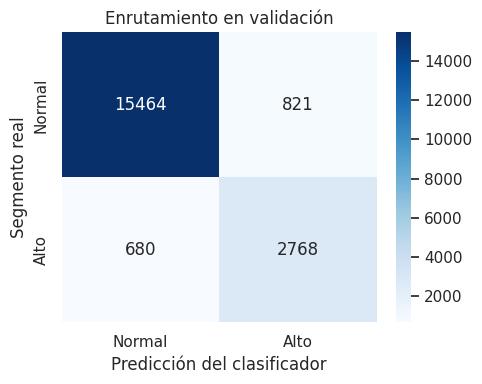

In [26]:
RUN_HYBRID_VALIDATION = True

if RUN_HYBRID_VALIDATION:
    if (not RUN_GATE_TRAINING or not RUN_NORMAL_REGRESSION or not RUN_HIGH_REGRESSION):
        raise RuntimeError(
            "Ejecuta antes el clasificador y los regresores segmentados."
        )

    validation_high_probability = (
        selected_gate_pipeline.predict_proba(
            validation_data[gate_features]
        )[:, 1]
    )
    validation_route_high = (
        validation_high_probability >= gate_threshold
    )

    validation_normal_prediction = (
        selected_normal_pipeline.predict(
            validation_data[normal_features]
        )
    )
    validation_high_prediction = (
        selected_high_pipeline.predict(
            validation_data[high_features]
        )
    )
    validation_hybrid_prediction = np.where(
        validation_route_high,
        validation_high_prediction,
        validation_normal_prediction,
    )

    hybrid_validation_metrics = regression_metrics(
        validation_data[TARGET],
        validation_hybrid_prediction,
    )
    hybrid_validation_metrics["WAPE"] = (
        np.abs(
            validation_data[TARGET].to_numpy()
            - validation_hybrid_prediction
        ).sum()
        / np.abs(validation_data[TARGET].to_numpy()).sum()
        * 100
    )

    actual_high_mask = (
        validation_data[TARGET] > HIGH_FREIGHT_LIMIT
    ).to_numpy()
    hybrid_validation_metrics["MAE_fletes_altos"] = (
        mean_absolute_error(
            validation_data.loc[
                actual_high_mask, TARGET
            ],
            validation_hybrid_prediction[actual_high_mask],
        )
    )
    hybrid_validation_metrics["sesgo_fletes_altos"] = np.mean(
        validation_data.loc[
            actual_high_mask, TARGET
        ].to_numpy()
        - validation_hybrid_prediction[actual_high_mask]
    )

    hybrid_validation_metrics_df = pd.DataFrame([{
        "clasificador": gate_model_name,
        "umbral": gate_threshold,
        "regresor_normal": normal_winner["modelo"],
        "regresor_alto": high_winner["modelo"],
        **hybrid_validation_metrics,
    }])
    display(hybrid_validation_metrics_df.style.format({
        "umbral": "{:.2f}",
        "MAE": "R$ {:.2f}",
        "RMSE": "R$ {:.2f}",
        "R2": "{:.3f}",
        "sesgo": "R$ {:.2f}",
        "WAPE": "{:.2f}%",
        "MAE_fletes_altos": "R$ {:.2f}",
        "sesgo_fletes_altos": "R$ {:.2f}",
    }))

    validation_cm = confusion_matrix(
        y_validation_gate,
        validation_route_high.astype(int),
    )
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        validation_cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Alto"],
        yticklabels=["Normal", "Alto"],
    )
    plt.xlabel("Predicción del clasificador")
    plt.ylabel("Segmento real")
    plt.title("Enrutamiento en validación")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Evaluación híbrida desactivada. "
        "Cambia RUN_HYBRID_VALIDATION a True."
    )

## 16. Entrenamiento final y prueba intacta

Cuando las tres piezas estén elegidas, se vuelven a entrenar usando todo el bloque de desarrollo. La prueba final se usa una sola vez.

El clasificador mantiene el umbral elegido en validación. Los dos regresores se ajustan con sus respectivos segmentos reales dentro del bloque de desarrollo.

In [27]:
RUN_FINAL_HYBRID = True

if RUN_FINAL_HYBRID:
    if not RUN_HYBRID_VALIDATION:
        raise RuntimeError(
            "Ejecuta primero la evaluación conjunta en validación."
        )

    y_development_gate = (
        development_data[TARGET] > HIGH_FREIGHT_LIMIT
    ).astype(int)

    final_gate_estimator = clone(
        CLASSIFIER_MODELS[gate_model_name]
    )
    if gate_model_name == "XGBoost":
        development_positive = max(
            int((y_development_gate == 1).sum()), 1
        )
        development_negative = int(
            (y_development_gate == 0).sum()
        )
        final_gate_estimator.set_params(
            scale_pos_weight=(
                development_negative / development_positive
            )
        )

    final_gate_pipeline = Pipeline([
        ("preprocessor", build_preprocessor(gate_features)),
        ("model", final_gate_estimator),
    ])
    final_gate_pipeline.fit(
        development_data[gate_features],
        y_development_gate,
    )

    normal_development_mask = (
        development_data[TARGET] <= HIGH_FREIGHT_LIMIT
    )
    high_development_mask = (
        development_data[TARGET] > HIGH_FREIGHT_LIMIT
    )

    final_normal_pipeline = Pipeline([
        ("preprocessor", build_preprocessor(normal_features)),
        (
            "model",
            clone(NORMAL_REGRESSION_MODELS[normal_winner["modelo"]]),
        ),
    ])
    final_normal_pipeline.fit(
        development_data.loc[
            normal_development_mask, normal_features
        ],
        development_data.loc[
            normal_development_mask, TARGET
        ],
    )

    final_high_pipeline = Pipeline([
        ("preprocessor", build_preprocessor(high_features)),
        (
            "model",
            clone(HIGH_MODEL_VARIANTS[high_winner["candidate_key"]]["estimator"]),
        ),
    ])
    final_high_fit_parameters = {}
    if bool(high_winner["usa_ponderacion"]):
        final_high_weights = np.where(
            development_data.loc[
                high_development_mask, TARGET
            ].to_numpy() > EXTREME_FREIGHT_LIMIT,
            EXTREME_FREIGHT_WEIGHT,
            1.0,
        )
        final_high_fit_parameters[
            "model__sample_weight"
        ] = final_high_weights

    final_high_pipeline.fit(
        development_data.loc[
            high_development_mask, high_features
        ],
        development_data.loc[
            high_development_mask, TARGET
        ],
        **final_high_fit_parameters,
    )

    test_high_probability = (
        final_gate_pipeline.predict_proba(
            test_data[gate_features]
        )[:, 1]
    )
    test_route_high = (
        test_high_probability >= gate_threshold
    )
    test_normal_prediction = (
        final_normal_pipeline.predict(
            test_data[normal_features]
        )
    )
    test_high_prediction = (
        final_high_pipeline.predict(
            test_data[high_features]
        )
    )
    test_hybrid_prediction = np.where(
        test_route_high,
        test_high_prediction,
        test_normal_prediction,
    )

    final_test_metrics = regression_metrics(
        test_data[TARGET],
        test_hybrid_prediction,
    )
    final_test_metrics["WAPE"] = (
        np.abs(
            test_data[TARGET].to_numpy()
            - test_hybrid_prediction
        ).sum()
        / np.abs(test_data[TARGET].to_numpy()).sum()
        * 100
    )

    test_actual_high = (
        test_data[TARGET] > HIGH_FREIGHT_LIMIT
    ).to_numpy()
    final_test_metrics["MAE_fletes_altos"] = (
        mean_absolute_error(
            test_data.loc[test_actual_high, TARGET],
            test_hybrid_prediction[test_actual_high],
        )
    )
    final_test_metrics["sesgo_fletes_altos"] = np.mean(
        test_data.loc[
            test_actual_high, TARGET
        ].to_numpy()
        - test_hybrid_prediction[test_actual_high]
    )

    test_gate_prediction = test_route_high.astype(int)
    final_test_metrics["precision_clase_alta"] = (
        precision_score(
            y_test_gate,
            test_gate_prediction,
            zero_division=0,
        )
    )
    final_test_metrics["recall_clase_alta"] = recall_score(
        y_test_gate,
        test_gate_prediction,
        zero_division=0,
    )
    final_test_metrics["F1_clase_alta"] = f1_score(
        y_test_gate,
        test_gate_prediction,
        zero_division=0,
    )

    final_metrics_df = pd.DataFrame([{
        "clasificador": gate_model_name,
        "regresor_normal": normal_winner["modelo"],
        "regresor_alto": high_winner["modelo"],
                "estrategia_alta": high_winner["estrategia"],
        "limite_brl": HIGH_FREIGHT_LIMIT,
        **final_test_metrics,
    }])
    display(final_metrics_df.style.format({
        "limite_brl": "R$ {:.2f}",
        "MAE": "R$ {:.2f}",
        "RMSE": "R$ {:.2f}",
        "R2": "{:.3f}",
        "sesgo": "R$ {:.2f}",
        "WAPE": "{:.2f}%",
        "MAE_fletes_altos": "R$ {:.2f}",
        "sesgo_fletes_altos": "R$ {:.2f}",
        "precision_clase_alta": "{:.3f}",
        "recall_clase_alta": "{:.3f}",
        "F1_clase_alta": "{:.3f}",
    }))

    original_reference = pd.DataFrame([{
        "sistema": "Regresor único anterior",
        "MAE": 5.53,
        "RMSE": 14.86,
        "R2": .668,
        "WAPE": 22.32,
        "MAE_fletes_altos": 18.04,
        "sesgo_fletes_altos": 15.93,
    }, {
        "sistema": "Primer sistema híbrido",
        "MAE": 5.48,
        "RMSE": 14.49,
        "R2": .684,
        "WAPE": 22.11,
        "MAE_fletes_altos": 15.54,
        "sesgo_fletes_altos": 11.70,
    }, {
        "sistema": "Sistema híbrido optimizado",
        "MAE": final_test_metrics["MAE"],
        "RMSE": final_test_metrics["RMSE"],
        "R2": final_test_metrics["R2"],
        "WAPE": final_test_metrics["WAPE"],
        "MAE_fletes_altos": final_test_metrics[
            "MAE_fletes_altos"
        ],
        "sesgo_fletes_altos": final_test_metrics[
            "sesgo_fletes_altos"
        ],
    }])
    display(Markdown(
        "### Comparación con el regresor único anterior"
    ))
    display(original_reference.style.format({
        "MAE": "R$ {:.2f}",
        "RMSE": "R$ {:.2f}",
        "R2": "{:.3f}",
        "WAPE": "{:.2f}%",
        "MAE_fletes_altos": "R$ {:.2f}",
        "sesgo_fletes_altos": "R$ {:.2f}",
    }))
else:
    print(
        "Entrenamiento final desactivado. "
        "Cambia RUN_FINAL_HYBRID a True."
    )

,clasificador,regresor_normal,regresor_alto,estrategia_alta,limite_brl,MAE,RMSE,R2,sesgo,WAPE,MAE_fletes_altos,sesgo_fletes_altos,precision_clase_alta,recall_clase_alta,F1_clase_alta
0,XGBoost,XGBoost,XGBoost,Cuantil 0.70,R$ 30.00,R$ 5.45,R$ 15.06,0.659,R$ 2.31,21.98%,R$ 15.09,R$ 10.08,0.805,0.845,0.825


### Comparación con el regresor único anterior

,sistema,MAE,RMSE,R2,WAPE,MAE_fletes_altos,sesgo_fletes_altos
0,Regresor único anterior,R$ 5.53,R$ 14.86,0.668,22.32%,R$ 18.04,R$ 15.93
1,Primer sistema híbrido,R$ 5.48,R$ 14.49,0.684,22.11%,R$ 15.54,R$ 11.70
2,Sistema híbrido optimizado,R$ 5.45,R$ 15.06,0.659,21.98%,R$ 15.09,R$ 10.08


## 17. Diagnóstico final

Un sistema híbrido puede fallar de dos maneras: el clasificador puede enviar el pedido al regresor equivocado o el regresor elegido puede calcular mal el precio. Por eso mostramos la matriz de enrutamiento, los residuos y el error por rango de flete.

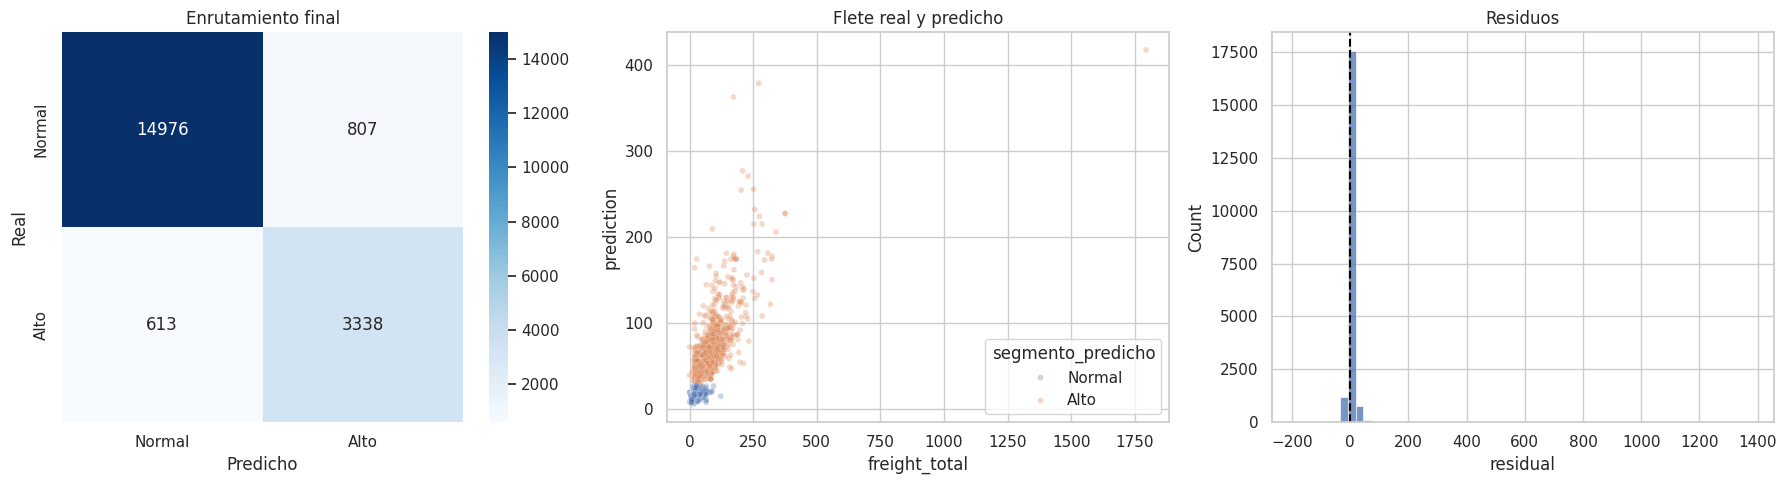

,rango_flete,pedidos,flete_promedio,MAE,sesgo,porcentaje_enviado_alto
0,Hasta R$15,5884,R$ 10.72,R$ 1.19,R$ -0.44,0.2%
1,R$15–30,9899,R$ 20.22,R$ 4.13,R$ 0.83,8.0%
2,R$30–60,2856,R$ 42.41,R$ 9.36,R$ 4.04,79.5%
3,Más de R$60,1095,R$ 95.72,R$ 30.03,R$ 25.85,97.5%


In [28]:
if RUN_FINAL_HYBRID:
    diagnostic = test_data[[
        "order_id",
        "order_purchase_timestamp",
        TARGET,
        "distance_km",
        "chargeable_weight_kg",
    ]].copy()
    diagnostic["probabilidad_flete_alto"] = (
        test_high_probability
    )
    diagnostic["segmento_predicho"] = np.where(
        test_route_high, "Alto", "Normal"
    )
    diagnostic["prediction"] = test_hybrid_prediction
    diagnostic["residual"] = (
        diagnostic[TARGET] - diagnostic["prediction"]
    )
    diagnostic["absolute_error"] = (
        diagnostic["residual"].abs()
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.heatmap(
        confusion_matrix(y_test_gate, test_gate_prediction),
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Alto"],
        yticklabels=["Normal", "Alto"],
        ax=axes[0],
    )
    axes[0].set_title("Enrutamiento final")
    axes[0].set_xlabel("Predicho")
    axes[0].set_ylabel("Real")

    sns.scatterplot(
        data=diagnostic,
        x=TARGET,
        y="prediction",
        hue="segmento_predicho",
        alpha=.3,
        s=18,
        ax=axes[1],
    )
    axes[1].set_title("Flete real y predicho")

    sns.histplot(
        diagnostic["residual"],
        bins=60,
        ax=axes[2],
    )
    axes[2].axvline(0, linestyle="--", color="black")
    axes[2].set_title("Residuos")
    plt.tight_layout()
    plt.show()

    diagnostic["rango_flete"] = pd.cut(
        diagnostic[TARGET],
        bins=[-np.inf, 15, 30, 60, np.inf],
        labels=[
            "Hasta R$15",
            "R$15–30",
            "R$30–60",
            "Más de R$60",
        ],
    )
    error_by_range = (
        diagnostic.groupby(
            "rango_flete", observed=False
        )
        .agg(
            pedidos=("order_id", "count"),
            flete_promedio=(TARGET, "mean"),
            MAE=("absolute_error", "mean"),
            sesgo=("residual", "mean"),
            porcentaje_enviado_alto=(
                "segmento_predicho",
                lambda values: (
                    values.eq("Alto").mean() * 100
                ),
            ),
        )
        .reset_index()
    )
    display(error_by_range.style.format({
        "flete_promedio": "R$ {:.2f}",
        "MAE": "R$ {:.2f}",
        "sesgo": "R$ {:.2f}",
        "porcentaje_enviado_alto": "{:.1f}%",
    }))

## 18. Exportación del sistema

Para facilitar el frontend se guarda un paquete con las tres piezas y sus variables. También se exportan por separado por si se necesita inspeccionarlas.

El frontend deberá calcular las mismas características, obtener la probabilidad de flete alto y aplicar el regresor correspondiente.

In [29]:
EXPORT_HYBRID_ARTIFACTS = True

if EXPORT_HYBRID_ARTIFACTS:
    if not RUN_FINAL_HYBRID:
        raise RuntimeError(
            "Ejecuta primero el entrenamiento final."
        )

    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

    # Exportación de los historiales utilizados durante la inferencia
    seller_history_export = (
        seller_development
        .rename("seller_historical_freight")
        .reset_index()
    )

    route_history_export = (
        route_development
        .rename("route_historical_freight")
        .reset_index()
    )

    seller_history_export.to_csv(
        ARTIFACT_DIR / "seller_freight_history.csv",
        index=False,
    )

    route_history_export.to_csv(
        ARTIFACT_DIR / "route_freight_history.csv",
        index=False,
    )

    hybrid_bundle = {
        "classifier": final_gate_pipeline,
        "classifier_features": gate_features,
        "classifier_threshold": gate_threshold,
        "normal_regressor": final_normal_pipeline,
        "normal_features": normal_features,
        "high_regressor": final_high_pipeline,
        "high_features": high_features,
        "high_freight_limit_brl": HIGH_FREIGHT_LIMIT,
        "extreme_freight_limit_brl": EXTREME_FREIGHT_LIMIT,
        "geographic_cluster_pipeline": geo_cluster_pipeline,

        # Referencias necesarias para pedidos nuevos
        "seller_freight_history": seller_development.to_dict(),
        "route_freight_history": route_development.to_dict(),
        "historical_freight_fallback": float(global_development),
    }

    joblib.dump(
        hybrid_bundle,
        ARTIFACT_DIR / "hybrid_model.joblib",
        compress=3,
    )
    joblib.dump(
        geo_cluster_pipeline,
        ARTIFACT_DIR / "geographic_clusters.joblib",
        compress=3,
    )
    joblib.dump(
        final_gate_pipeline,
        ARTIFACT_DIR / "freight_classifier.joblib",
        compress=3,
    )
    joblib.dump(
        final_normal_pipeline,
        ARTIFACT_DIR / "normal_freight_model.joblib",
        compress=3,
    )
    joblib.dump(
        final_high_pipeline,
        ARTIFACT_DIR / "high_freight_model.joblib",
        compress=3,
    )

    gate_results_df.to_csv(
        ARTIFACT_DIR / "classifier_metrics.csv",
        index=False,
    )
    normal_results_df.to_csv(
        ARTIFACT_DIR / "normal_regression_metrics.csv",
        index=False,
    )
    high_results_df.to_csv(
        ARTIFACT_DIR / "high_regression_metrics.csv",
        index=False,
    )
    final_metrics_df.to_csv(
        ARTIFACT_DIR / "metrics.csv",
        index=False,
    )
    feature_importance_df.to_csv(
        ARTIFACT_DIR / "feature_importance.csv",
        index=False,
    )
    high_feature_importance_df.to_csv(
        ARTIFACT_DIR / "high_feature_importance.csv",
        index=False,
    )

    prediction_export = diagnostic[[
        "order_id",
        "order_purchase_timestamp",
        TARGET,
        "probabilidad_flete_alto",
        "segmento_predicho",
        "prediction",
        "absolute_error",
    ]].copy()

    prediction_export.to_csv(
        ARTIFACT_DIR / "predictions.csv",
        index=False,
    )

    manifest = {
        "module": "hybrid_freight_regression",
        "target": TARGET,
        "currency": "BRL",
        "high_freight_limit": HIGH_FREIGHT_LIMIT,
        "classifier": {
            "model": gate_model_name,
            "subset": gate_subset_name,
            "features": gate_features,
            "probability_threshold": gate_threshold,
        },
        "normal_regressor": {
            "model": normal_winner["modelo"],
            "subset": normal_winner["subconjunto"],
            "features": normal_features,
        },
        "high_regressor": {
            "model": high_winner["modelo"],
            "strategy": high_winner["estrategia"],
            "subset": high_winner["subconjunto"],
            "features": high_features,
        },

        # Archivos y valor de respaldo para las variables históricas
        "historical_features": {
            "seller_file": "seller_freight_history.csv",
            "route_file": "route_freight_history.csv",
            "fallback_brl": float(global_development),
        },

        "test_metrics": {
            name: float(value)
            for name, value in final_test_metrics.items()
        },
        "split": {
            "train": .60,
            "validation": .20,
            "test": .20,
            "type": "temporal",
        },
        "random_state": RANDOM_STATE,
    }

    with open(
        ARTIFACT_DIR / "manifest.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            manifest,
            file,
            ensure_ascii=False,
            indent=2,
        )

    print("Artefactos exportados en:", ARTIFACT_DIR)

Artefactos exportados en: /kaggle/working/artifacts/freight_regression


## 19. Comparación y conclusión pendiente

Esta versión solo será mejor si reduce el MAE y el sesgo de los fletes mayores de 60 BRL sin deteriorar de forma importante el desempeño general.

Al finalizar se debe comparar contra:

- el regresor único original;
- el primer sistema híbrido;
- esta versión optimizada para la cola cara.

También se revisará si los clústeres geográficos aparecen entre las variables importantes, qué estrategia ganó para el modelo caro y cuánto pesan los artefactos exportados. Si la mejora es pequeña, debe conservarse la versión más sencilla.